# Clustering với DBSCAN

Nguồn: https://www.digitalvidya.com/blog/the-top-5-clustering-algorithms-data-scientists-should-know/
![image.png](https://imgur.com/9D6aAF2.gif)

**Cách chạy:** chọn Run All. Notebook tự tạo 225 điểm, không cần CSV hay tải dữ liệu. Cần numpy, pandas, matplotlib và scikit-learn. Đã điền đầy đủ các ô và phần tính silhouette thủ công, kể cả so sánh khi giữ noise.


In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

np.set_printoptions(precision=3, suppress=True)

## 1. Dữ liệu giả định
(Cùng dữ liệu giả với `03_Demo-kMeans.ipynb`)

In [2]:
np.random.seed(1)
x1,y1 = np.random.normal(loc=2,scale=1,size=50), np.random.normal(loc=5,scale=1,size=50)
x2,y2 = np.random.normal(loc=5,scale=1,size=75), np.random.normal(loc=1,scale=1,size=75)
x3,y3 = np.random.normal(loc=8,scale=1,size=100), np.random.normal(loc=7,scale=1,size=100)

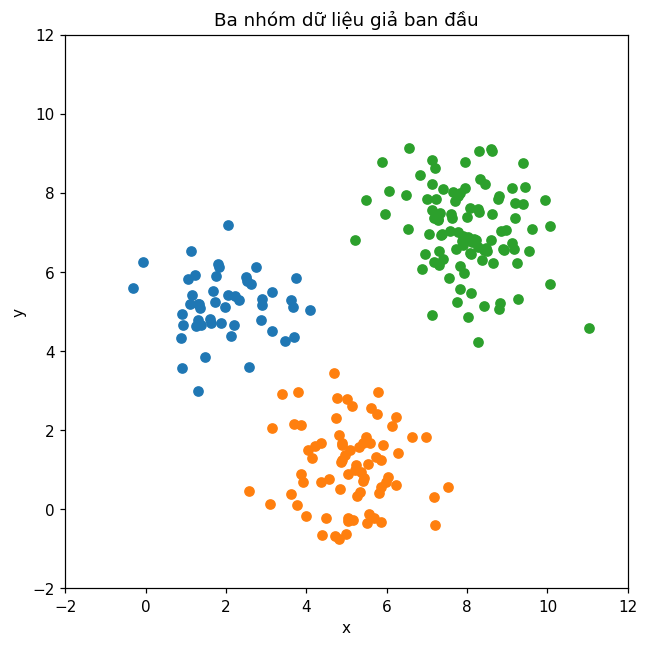

In [3]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(x1, y1)
plt.scatter(x2, y2)
plt.scatter(x3, y3)
plt.title('Ba nhóm dữ liệu giả ban đầu')
plt.xlabel('x'); plt.ylabel('y')
plt.tight_layout()
plt.show()

### Ghép nối dữ liệu lại thành 1 tập

In [4]:
dat1 = np.stack([x1,y1]).T
dat1.shape

(50, 2)


In [5]:
dat2 = np.stack([x2,y2]).T
dat3 = np.stack([x3,y3]).T

In [6]:
dat = np.vstack([dat1, dat2, dat3])
dat.shape

(225, 2)


### Sắp ngẫu nhiên các dòng

In [7]:
np.random.seed(2)
np.random.shuffle(dat)

### Kiểm tra lại với biểu đồ scatter

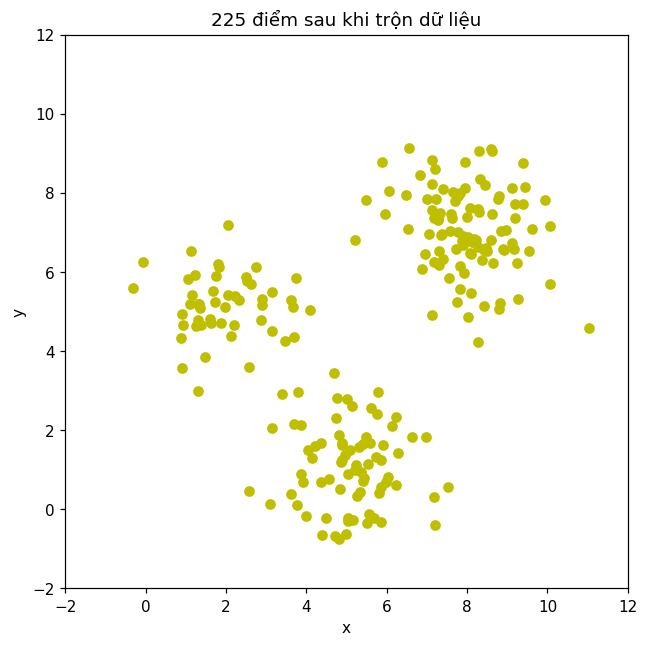

In [8]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.title('225 điểm sau khi trộn dữ liệu')
plt.xlabel('x'); plt.ylabel('y')
plt.tight_layout()
plt.show()

## 2. Thực hiện phân cụm bằng DBSCAN

**=== Import lớp DBSCAN từ thư viện sklearn ===**

In [9]:
from sklearn.cluster import DBSCAN

### 2.1. Khởi tạo model và fit vào dữ liệu

In [10]:
# eps: bán kính lân cận; min_samples có tính cả chính điểm đang xét.
model = DBSCAN(eps=1, min_samples=5, metric='euclidean')


**=== Thực hiện fit vào dữ liệu ===**

In [11]:
model.fit(dat)
print('Đã phân cụm', len(dat), 'điểm.')


Đã phân cụm 225 điểm.


### 2.2. Kiểm tra kết quả các cluster tìm được

**=== Lấy ra nhãn các clusters ===**

In [12]:
cluster = model.labels_
print('Nhãn -1 là noise; nhãn 0, 1,... là các cụm được phát hiện.')


Nhãn -1 là noise; nhãn 0, 1,... là các cụm được phát hiện.


In [13]:
cluster

array([ 0,  0,  2,  1,  1,  2,  0,  1,  1,  1,  1,  0,  0,  2,  2,  0,  2,
        0,  1,  2,  1,  0,  0,  2,  0,  0,  1,  1,  1,  0,  0,  2,  2,  1,
        1,  1,  0,  2,  2,  2,  2,  2,  0, -1,  0, -1,  1,  2,  0,  2,  0,
        1,  2,  0,  1,  0,  0,  1,  0,  0,  0,  1,  0,  0,  0,  0,  2,  1,
        2,  0,  0,  0, -1,  2,  2,  0,  0,  1,  0,  0,  0,  0,  0,  0,  1,
        0,  0, -1, -1,  0,  0,  2,  0,  0,  0,  0,  1,  1,  1,  0,  0,  2,
        0,  0,  0,  1,  1, -1,  0, -1,  1,  0,  1,  0,  0,  0,  1,  1,  2,
        1,  0,  0,  0,  0,  0,  0,  0,  2,  1,  1,  2,  2,  1,  0,  0,  0,
        2,  1,  0,  0,  1,  1,  2,  0,  0,  1,  0,  1,  0,  1,  1,  1,  0,
        1,  2,  1,  1,  0,  1,  2,  2,  0,  1,  0,  2,  2,  0,  1,  1,  1,
        1,  1,  1,  0,  0,  0,  0,  0,  0,  2,  2,  0,  0,  1,  1,  1,  0,
        1,  0,  2,  1,  1,  1,  0,  1,  2,  2,  1,  1,  1,  0,  2,  1,  0,
        0,  2,  1,  1,  0,  2,  1,  2,  0,  1,  0,  0,  2,  1,  1,  0,  2,
        2,  1,  2,  0])


**=== Đếm xem mỗi cluster có bao nhiêu điểm ===**

In [14]:
nhan, so_luong = np.unique(cluster, return_counts=True)
for label, count in zip(nhan, so_luong):
    ten = 'Noise' if label == -1 else f'Cụm {label}'
    print(f'{ten}: {count} điểm')
so_cum = len(set(cluster)) - (1 if -1 in cluster else 0)
print('Số cụm (không tính noise):', so_cum)
print('Tổng số điểm:', so_luong.sum())


Noise: 7 điểm
Cụm 0: 98 điểm
Cụm 1: 73 điểm
Cụm 2: 47 điểm
Số cụm (không tính noise): 3
Tổng số điểm: 225


**=== Hiển thị lên biểu đồ ===**

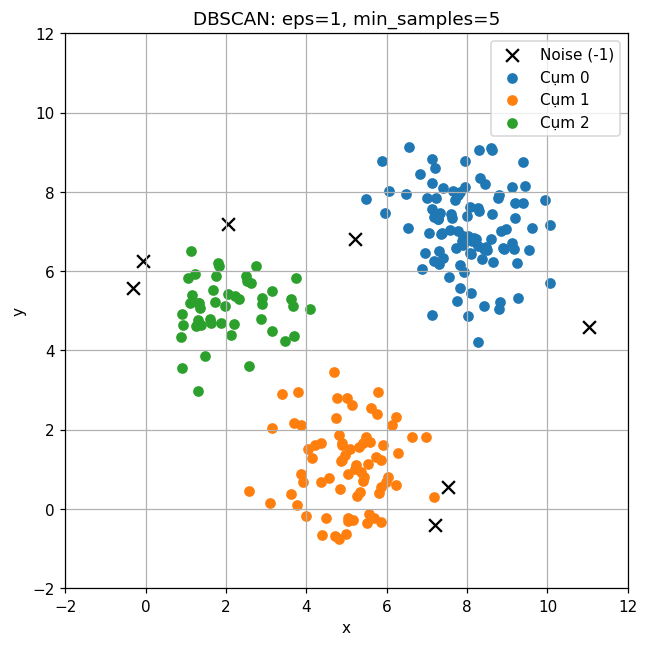

In [15]:
plt.figure(figsize=(6, 6))
plt.xlim([-2, 12]); plt.ylim([-2, 12])
for label in np.unique(cluster):
    points = dat[cluster == label]
    if label == -1:
        plt.scatter(points[:, 0], points[:, 1], c='black', marker='x', s=70, label='Noise (-1)')
    else:
        plt.scatter(points[:, 0], points[:, 1], label=f'Cụm {label}')
plt.title('DBSCAN: eps=1, min_samples=5')
plt.xlabel('x'); plt.ylabel('y')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()


### 2.3. Tính hiệu suất phân cụm

**=== Thử tính với hàm built-in của Sklearn ===**

In [16]:
from sklearn.metrics import silhouette_score

In [17]:
# Sklearn coi -1 như một nhãn cụm bình thường khi tính silhouette.
if 2 <= len(np.unique(cluster)) < len(dat):
    score_all = silhouette_score(dat, cluster)
    print(f'Silhouette sklearn, gồm noise: {score_all:.6f}')
else:
    score_all = np.nan
    print('Không tính được silhouette: cần từ 2 đến n-1 nhóm nhãn.')
print('Silhouette nằm trong [-1, 1], càng cao càng cho thấy các cụm tách biệt hơn.')
print('Đây là chỉ số chất lượng phân cụm, không phải accuracy hay tỷ lệ dự đoán đúng.')


Silhouette sklearn, gồm noise: 0.639460
Silhouette nằm trong [-1, 1], càng cao càng cho thấy các cụm tách biệt hơn.
Đây là chỉ số chất lượng phân cụm, không phải accuracy hay tỷ lệ dự đoán đúng.


**=== Tính lại với các cụm không chứa điểm noise ===**

In [18]:
import pandas as pd

In [19]:
# Boolean mask: chỉ giữ điểm có nhãn khác -1.
mask = cluster != -1
dat2 = dat[mask]
cluster2 = cluster[mask]
print('Số điểm ban đầu:', len(dat))
print('Số điểm noise đã bỏ:', np.sum(~mask))
print('Số điểm còn lại:', len(dat2))
print('Kích thước dat2, cluster2:', dat2.shape, cluster2.shape)


Số điểm ban đầu: 225
Số điểm noise đã bỏ: 7
Số điểm còn lại: 218
Kích thước dat2, cluster2: (218, 2) (218,)


In [20]:
def silhouette_thu_cong(data, labels):
    """Tính silhouette từng điểm bằng NumPy/Pandas, không gọi silhouette_samples."""
    data = np.asarray(data)
    labels = np.asarray(labels)
    if not (2 <= len(np.unique(labels)) < len(data)):
        raise ValueError('Silhouette cần từ 2 đến n-1 nhóm nhãn.')

    s_list = []
    for i, sample in enumerate(data):
        label = labels[i]

        # Bỏ chính sample, không bỏ những điểm khác có cùng tọa độ.
        other_samples = np.delete(data, i, axis=0)
        other_labels = np.delete(labels, i)

        # Khoảng cách Euclid từ sample đến mọi điểm còn lại.
        distances = np.sqrt(np.sum((other_samples - sample)**2, axis=1))
        frame = pd.DataFrame({'distance': distances, 'cluster': other_labels})
        mean_distance = frame.groupby('cluster')['distance'].mean()

        # Cụm chỉ có một điểm: silhouette của điểm đó được quy ước bằng 0.
        if label not in mean_distance.index:
            s_list.append(0.0)
            continue

        # p (a): khoảng cách trung bình đến các điểm khác cùng cụm.
        p = mean_distance.loc[label]
        # q (b): khoảng cách trung bình nhỏ nhất đến một cụm khác.
        q = mean_distance.drop(index=label).min()
        # q không phải khoảng cách đến một điểm gần nhất, cũng không phải đến tâm.
        denominator = max(p, q)
        s = (q - p) / denominator if denominator > 0 else 0.0
        s_list.append(float(s))
    return s_list

# Tính cho các điểm không phải noise.
s_list = silhouette_thu_cong(dat2, cluster2)
print('10 hệ số đầu tiên:', np.round(s_list[:10], 6))


10 hệ số đầu tiên: [0.489 0.787 0.567 0.674 0.738 0.754 0.795 0.602 0.758 0.715]


In [21]:
score_manual = np.mean(s_list)
score_clean = silhouette_score(dat2, cluster2)
print(f'Silhouette tự tính, bỏ noise: {score_manual:.6f}')
print(f'Silhouette sklearn, bỏ noise: {score_clean:.6f}')
print(f'Chênh lệch: {abs(score_manual - score_clean):.12f}')
assert np.isclose(score_manual, score_clean), 'Cần kiểm tra lại công thức tự tính.'
print('Hai cách tính khớp nhau.')


Silhouette tự tính, bỏ noise: 0.685423
Silhouette sklearn, bỏ noise: 0.685423
Chênh lệch: 0.000000000000
Hai cách tính khớp nhau.


**==> Thử thực hiện lại mà không bỏ giá trị noise?**

In [22]:
# Lặp lại công thức tự tính trên TOÀN BỘ dữ liệu, coi -1 là một nhóm nhãn.
s_all = silhouette_thu_cong(dat, cluster)
score_manual_all = np.mean(s_all)
print(f'Tự tính, gồm noise: {score_manual_all:.6f}')
print(f'Sklearn, gồm noise: {score_all:.6f}')
assert np.isclose(score_manual_all, score_all)
print(f'Bỏ noise: {score_clean:.6f}')
print(f'Chênh lệch (bỏ noise - gồm noise): {score_clean - score_all:.6f}')
print('Nhận xét: điểm noise là các điểm rời rạc; gom tất cả thành một cụm -1 để '
      'tính silhouette có thể làm cách đọc chỉ số bị sai lệch.')
print('Nên báo silhouette trên các cụm không chứa noise kèm số/tỷ lệ noise: '
      f'{np.sum(cluster == -1)}/{len(dat)} = {np.mean(cluster == -1):.2%}.')
print('Hai chỉ số dùng hai tập điểm khác nhau; tăng sau khi bỏ noise không tự nó chứng minh mô hình tốt hơn.')


Tự tính, gồm noise: 0.639460
Sklearn, gồm noise: 0.639460
Bỏ noise: 0.685423
Chênh lệch (bỏ noise - gồm noise): 0.045963
Nhận xét: điểm noise là các điểm rời rạc; gom tất cả thành một cụm -1 để tính silhouette có thể làm cách đọc chỉ số bị sai lệch.
Nên báo silhouette trên các cụm không chứa noise kèm số/tỷ lệ noise: 7/225 = 3.11%.
Hai chỉ số dùng hai tập điểm khác nhau; tăng sau khi bỏ noise không tự nó chứng minh mô hình tốt hơn.
